
DATASET: JARVIS18 (jarvis18)
Common materials across X and all three y files: 17067
Explained variance: PC1 = 16.22% | PC2 = 9.40%
Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\jarvis18_PCA_outcome_maps_property_specific_norms_units.png


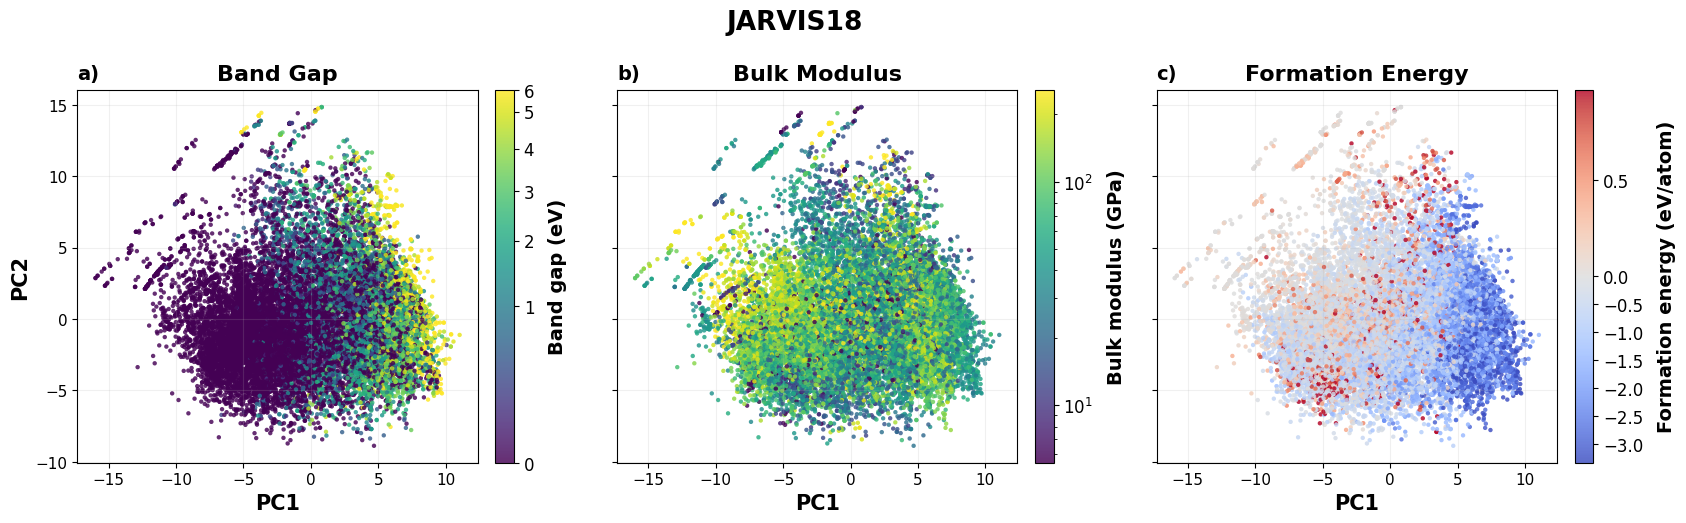


DATASET: JARVIS22 (jarvis22)
Common materials across X and all three y files: 21124
Explained variance: PC1 = 15.90% | PC2 = 9.89%
Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\jarvis22_PCA_outcome_maps_property_specific_norms_units.png


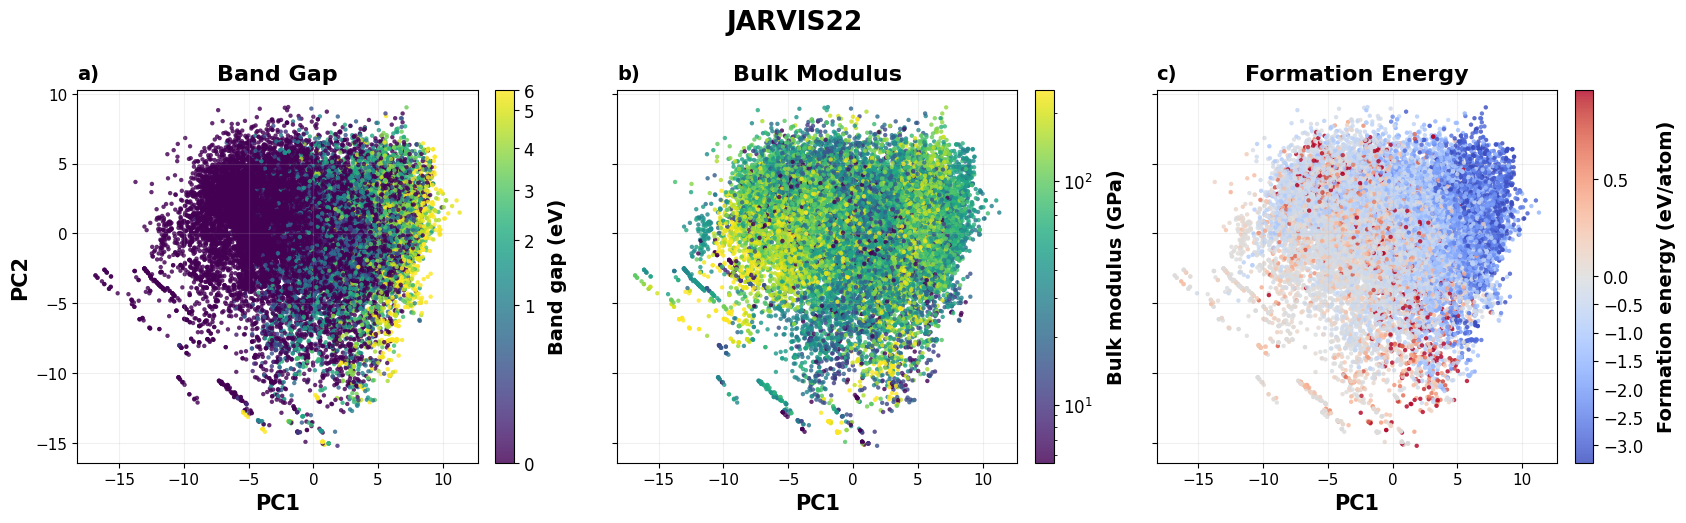


DATASET: MP18 (mp18)
Common materials across X and all three y files: 6281
Explained variance: PC1 = 18.26% | PC2 = 9.41%
Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\mp18_PCA_outcome_maps_property_specific_norms_units.png


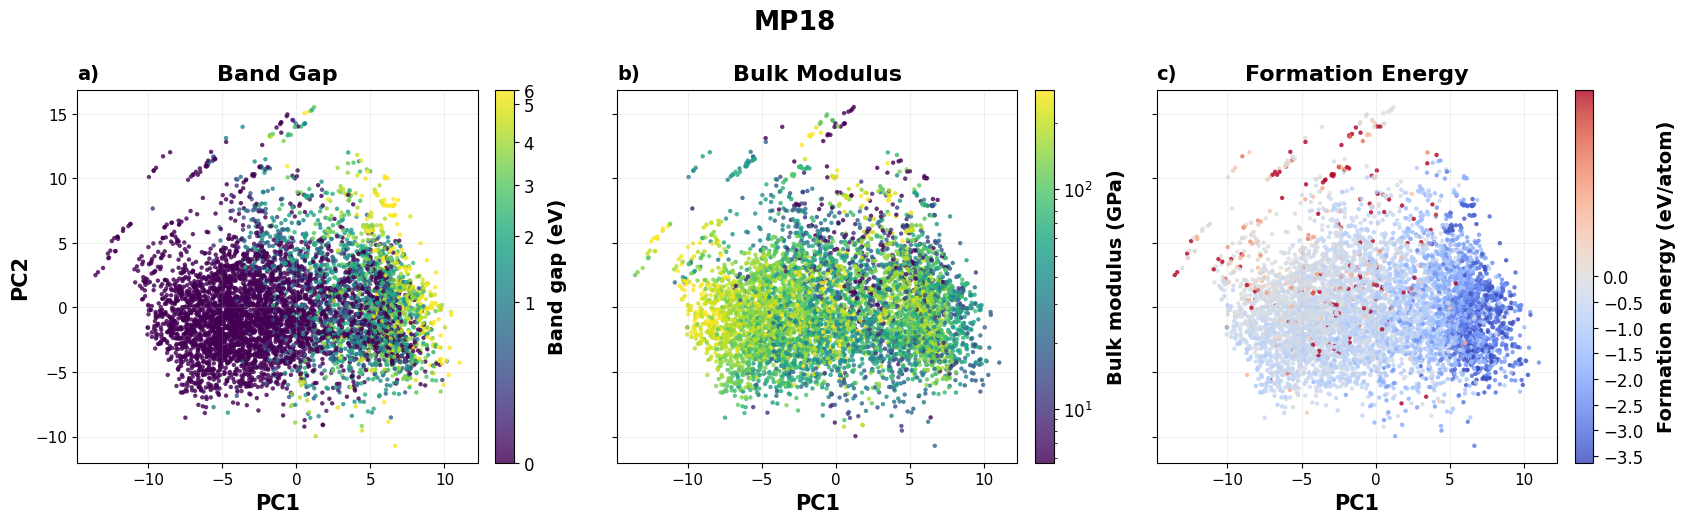


DATASET: MP21 (mp21)
Common materials across X and all three y files: 6400
Explained variance: PC1 = 18.12% | PC2 = 9.40%
Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\mp21_PCA_outcome_maps_property_specific_norms_units.png


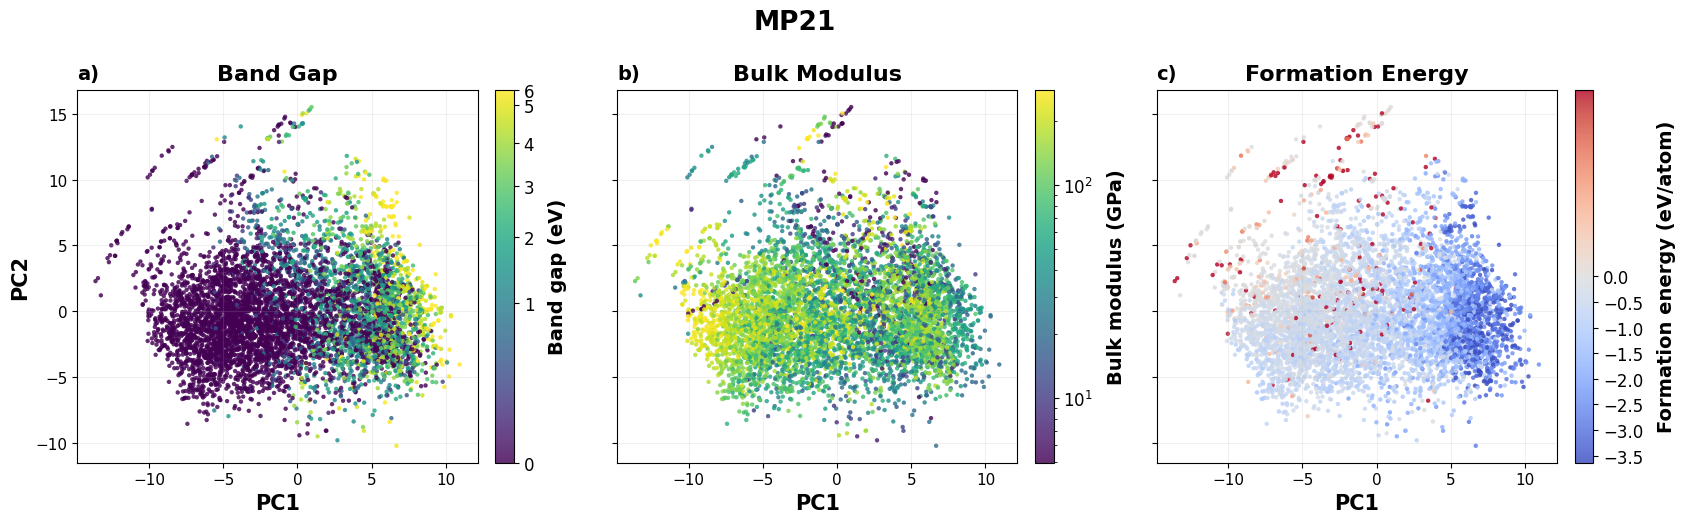


Saved PCA summary:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\ALL4_DFT_PCA_explained_variance_summary.csv


In [14]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


# =============================================================================
# Configuration
# =============================================================================

BASE = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
    r"\WITH_MODIFICATIONS"
)

# Iterate over all four DFT datasets.
DATASETS = {
    "JARVIS18": "jarvis18",
    "JARVIS22": "jarvis22",
    "MP18": "mp18",
    "MP21": "mp21",
}

# y-file convention used throughout the project:
# y1 = formation energy
# y2 = bulk modulus
# y3 = band gap
PROPERTY_INFO = {
    "Bandgap": {
        "y_number": 3,
        "title": "Band Gap",
        "colorbar_label": "Band gap (eV)",
        "cmap": "viridis",
    },
    "Bulk Modulus": {
        "y_number": 2,
        "title": "Bulk Modulus",
        "colorbar_label": "Bulk modulus (GPa)",
        "cmap": "viridis",
    },
    "Formation Energy": {
        "y_number": 1,
        "title": "Formation Energy",
        "colorbar_label": "Formation energy (eV/atom)",
        "cmap": "coolwarm",
    },
}

# Plot settings
FIGSIZE = (16.5, 5.4)
POINT_SIZE = 10
POINT_ALPHA = 0.82

# Larger colorbar labels/ticks
COLORBAR_LABEL_SIZE = 14
COLORBAR_TICK_SIZE = 12

# Percentile clipping reduces domination by a small number of extreme values.
LOW_PERCENTILE = 2
HIGH_PERCENTILE = 98

SAVE_DPI = 300


# =============================================================================
# Data loading
# =============================================================================

def load_x_table(path):
    """
    Load feature table.

    First column:
        independent material identifier

    Remaining columns:
        feature values
    """
    df = pd.read_csv(path)

    if df.shape[1] < 2:
        raise ValueError(
            f"Expected ID column + feature columns in:\n{path}"
        )

    ids = df.iloc[:, 0].rename("material_id")

    X_num = (
        df.iloc[:, 1:]
        .apply(pd.to_numeric, errors="coerce")
    )

    # Keep only columns containing at least one numeric value.
    valid_cols = [
        col
        for col in X_num.columns
        if X_num[col].notna().any()
    ]

    X_num = X_num[valid_cols].copy()

    out = pd.concat(
        [ids, X_num],
        axis=1,
    )

    out = out[
        out["material_id"].notna()
    ].copy()

    if out["material_id"].duplicated().any():

        dup = (
            out.loc[
                out["material_id"].duplicated(),
                "material_id",
            ]
            .head(10)
            .tolist()
        )

        raise ValueError(
            f"Duplicate material IDs found in X file:\n"
            f"{path}\n"
            f"Examples: {dup}"
        )

    return out.reset_index(drop=True)


def load_y_table(path, property_name):
    """
    Load outcome table.

    First column:
        independent material identifier

    Last numeric column after the identifier:
        outcome value
    """
    df = pd.read_csv(path)

    if df.shape[1] < 2:
        raise ValueError(
            f"Expected ID column + outcome column in:\n{path}"
        )

    ids = df.iloc[:, 0]

    numeric = (
        df.iloc[:, 1:]
        .apply(pd.to_numeric, errors="coerce")
    )

    valid_numeric_cols = [
        col
        for col in numeric.columns
        if numeric[col].notna().any()
    ]

    if not valid_numeric_cols:
        raise ValueError(
            f"No numeric outcome column found in:\n{path}"
        )

    y_col = valid_numeric_cols[-1]

    out = pd.DataFrame({
        "material_id": ids,
        property_name: numeric[y_col],
    })

    out = out[
        out["material_id"].notna()
        & out[property_name].notna()
        & np.isfinite(out[property_name])
    ].copy()

    if out["material_id"].duplicated().any():

        dup = (
            out.loc[
                out["material_id"].duplicated(),
                "material_id",
            ]
            .head(10)
            .tolist()
        )

        raise ValueError(
            f"Duplicate material IDs found in y file:\n"
            f"{path}\n"
            f"Examples: {dup}"
        )

    out[property_name] = (
        out[property_name]
        .astype(float)
    )

    return out.reset_index(drop=True)


# =============================================================================
# Property-specific color normalization
# =============================================================================

def get_property_norm(property_name, values):
    """
    Property-specific color normalization.

    Band gap:
        PowerNorm(gamma=0.5), preserving zero and expanding lower values.

    Bulk modulus:
        LogNorm, expanding low/intermediate positive values.

    Formation energy:
        TwoSlopeNorm centered at zero.

    Percentile clipping limits the effect of extreme outliers.
    """

    values = np.asarray(values, dtype=float)

    finite = values[np.isfinite(values)]

    if len(finite) == 0:
        raise ValueError(
            f"No finite values for {property_name}"
        )

    # -------------------------------------------------------------------------
    # Band gap
    # -------------------------------------------------------------------------
    if property_name == "Bandgap":

        vmin = 0.0
        vmax = np.percentile(
            finite,
            HIGH_PERCENTILE,
        )

        if vmax <= vmin:
            vmax = np.max(finite)

        return colors.PowerNorm(
            gamma=0.5,
            vmin=vmin,
            vmax=vmax,
            clip=True,
        )

    # -------------------------------------------------------------------------
    # Bulk modulus
    # -------------------------------------------------------------------------
    elif property_name == "Bulk Modulus":

        positive = finite[finite > 0]

        if len(positive) == 0:
            raise ValueError(
                "Bulk modulus contains no positive values, "
                "so LogNorm cannot be used."
            )

        vmin = np.percentile(
            positive,
            LOW_PERCENTILE,
        )

        vmax = np.percentile(
            positive,
            HIGH_PERCENTILE,
        )

        if vmin <= 0:
            vmin = np.min(positive)

        if vmax <= vmin:
            vmax = np.max(positive)

        return colors.LogNorm(
            vmin=vmin,
            vmax=vmax,
            clip=True,
        )

    # -------------------------------------------------------------------------
    # Formation energy
    # -------------------------------------------------------------------------
    elif property_name == "Formation Energy":

        vmin = np.percentile(
            finite,
            LOW_PERCENTILE,
        )

        vmax = np.percentile(
            finite,
            HIGH_PERCENTILE,
        )

        if vmin >= 0:
            vmin = np.min(finite)

        if vmax <= 0:
            vmax = np.max(finite)

        if not (vmin < 0 < vmax):

            vmax_abs = max(
                abs(np.min(finite)),
                abs(np.max(finite)),
            )

            vmin = -vmax_abs
            vmax = vmax_abs

        return colors.TwoSlopeNorm(
            vmin=vmin,
            vcenter=0.0,
            vmax=vmax,
        )

    return colors.Normalize(
        vmin=np.min(finite),
        vmax=np.max(finite),
    )


# =============================================================================
# Analyze and plot one dataset
# =============================================================================

def plot_dataset(dataset_label, dataset_key):

    print("\n" + "=" * 100)
    print(f"DATASET: {dataset_label} ({dataset_key})")
    print("=" * 100)

    # -------------------------------------------------------------------------
    # Paths
    # -------------------------------------------------------------------------
    x_file = BASE / f"xTrainVal_{dataset_key}.csv"

    if not x_file.exists():
        raise FileNotFoundError(
            f"Feature file does not exist:\n{x_file}"
        )

    y_files = {
        property_name: (
            BASE
            / f"y{info['y_number']}TrainVal_{dataset_key}.csv"
        )
        for property_name, info in PROPERTY_INFO.items()
    }

    for property_name, y_file in y_files.items():

        if not y_file.exists():
            raise FileNotFoundError(
                f"{property_name} file does not exist:\n{y_file}"
            )

    # -------------------------------------------------------------------------
    # Load and ID-align X and all outcomes
    # -------------------------------------------------------------------------
    x_df = load_x_table(x_file)

    merged = x_df.copy()

    for property_name, y_path in y_files.items():

        y_df = load_y_table(
            y_path,
            property_name,
        )

        merged = merged.merge(
            y_df,
            on="material_id",
            how="inner",
        )

    print(
        "Common materials across X and all three y files: "
        f"{len(merged)}"
    )

    # -------------------------------------------------------------------------
    # PCA on standardized feature space
    # -------------------------------------------------------------------------
    feature_cols = [
        col
        for col in x_df.columns
        if col != "material_id"
    ]

    X = (
        merged[feature_cols]
        .to_numpy(dtype=float)
    )

    imputer = SimpleImputer(
        strategy="median"
    )

    X_imputed = imputer.fit_transform(X)

    scaler = StandardScaler()

    X_scaled = scaler.fit_transform(
        X_imputed
    )

    pca = PCA(
        n_components=2
    )

    scores = pca.fit_transform(
        X_scaled
    )

    merged["PC1"] = scores[:, 0]
    merged["PC2"] = scores[:, 1]

    explained = (
        100
        * pca.explained_variance_ratio_
    )

    print(
        f"Explained variance: "
        f"PC1 = {explained[0]:.2f}% | "
        f"PC2 = {explained[1]:.2f}%"
    )

    # -------------------------------------------------------------------------
    # Figure
    # -------------------------------------------------------------------------
    fig, axes = plt.subplots(
        1,
        3,
        figsize=FIGSIZE,
        sharex=True,
        sharey=True,
    )

    panel_info = [
        ("Bandgap", "a)"),
        ("Bulk Modulus", "b)"),
        ("Formation Energy", "c)"),
    ]

    for ax, (
        property_name,
        panel_label,
    ) in zip(
        axes,
        panel_info,
    ):

        info = PROPERTY_INFO[property_name]

        values = (
            merged[property_name]
            .to_numpy(dtype=float)
        )

        norm = get_property_norm(
            property_name,
            values,
        )

        scatter = ax.scatter(
            merged["PC1"],
            merged["PC2"],
            c=values,
            cmap=info["cmap"],
            norm=norm,
            s=POINT_SIZE,
            alpha=POINT_ALPHA,
            linewidths=0,
            rasterized=True,
        )

        # -------------------------------------------------------------
        # Panel title
        # -------------------------------------------------------------
        ax.set_title(
            info["title"],
            fontsize=16,
            fontweight="bold",
            pad=7,
        )

        # -------------------------------------------------------------
        # Axes
        # -------------------------------------------------------------
        ax.set_xlabel(
            "PC1",
            fontsize=15,
            fontweight="bold",
        )

        ax.grid(
            alpha=0.18
        )

        ax.tick_params(
            axis="both",
            labelsize=11,
        )

        # -------------------------------------------------------------
        # Panel label
        # -------------------------------------------------------------
        ax.text(
            0.00,
            1.02,
            panel_label,
            transform=ax.transAxes,
            ha="left",
            va="bottom",
            fontsize=14,
            fontweight="bold",
        )

        # -------------------------------------------------------------
        # Colorbar
        # -------------------------------------------------------------
        cbar = fig.colorbar(
            scatter,
            ax=ax,
            fraction=0.047,
            pad=0.04,
        )

        # Bigger colorbar tick labels.
        cbar.ax.tick_params(
            labelsize=COLORBAR_TICK_SIZE,
        )

        # Bigger colorbar title WITH units.
        cbar.set_label(
            info["colorbar_label"],
            fontsize=COLORBAR_LABEL_SIZE,
            fontweight="bold",
            labelpad=10,
        )

    # -------------------------------------------------------------------------
    # Shared y-axis
    # -------------------------------------------------------------------------
    axes[0].set_ylabel(
        "PC2",
        fontsize=15,
        fontweight="bold",
    )

    # -------------------------------------------------------------------------
    # Main title
    # -------------------------------------------------------------------------
    fig.suptitle(
        dataset_label,
        fontsize=19,
        fontweight="bold",
        y=0.99,
    )

    # -------------------------------------------------------------------------
    # Layout
    # -------------------------------------------------------------------------
    fig.subplots_adjust(
        top=0.84,
        bottom=0.15,
        left=0.065,
        right=0.985,
        wspace=0.23,
    )

    # -------------------------------------------------------------------------
    # Save
    # -------------------------------------------------------------------------
    output_fig = (
        BASE
        / (
            f"{dataset_key}_PCA_outcome_maps_"
            f"property_specific_norms_units.png"
        )
    )

    fig.savefig(
        output_fig,
        dpi=SAVE_DPI,
        bbox_inches="tight",
    )

    print(
        f"Saved figure:\n{output_fig}"
    )

    plt.show()
    plt.close(fig)

    return {
        "dataset": dataset_label,
        "dataset_key": dataset_key,
        "N_common": len(merged),
        "PC1_explained_variance_percent": explained[0],
        "PC2_explained_variance_percent": explained[1],
    }


# =============================================================================
# Run all four datasets
# =============================================================================

summary_records = []

for dataset_label, dataset_key in DATASETS.items():

    result = plot_dataset(
        dataset_label=dataset_label,
        dataset_key=dataset_key,
    )

    summary_records.append(result)


# =============================================================================
# Save PCA summary
# =============================================================================

summary_df = pd.DataFrame(
    summary_records
)

summary_output = (
    BASE
    / "ALL4_DFT_PCA_explained_variance_summary.csv"
)

summary_df.to_csv(
    summary_output,
    index=False,
)

print("\n" + "=" * 100)
print("Saved PCA summary:")
print(summary_output)
print("=" * 100)


Common materials used for the combined figure: 17067
Explained variance: PC1=16.22% | PC2=9.40%
Saved figure:
C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2\WITH_MODIFICATIONS\jarvis18_bandgap_combined_PCA_policies_violin_25_50_updated.png


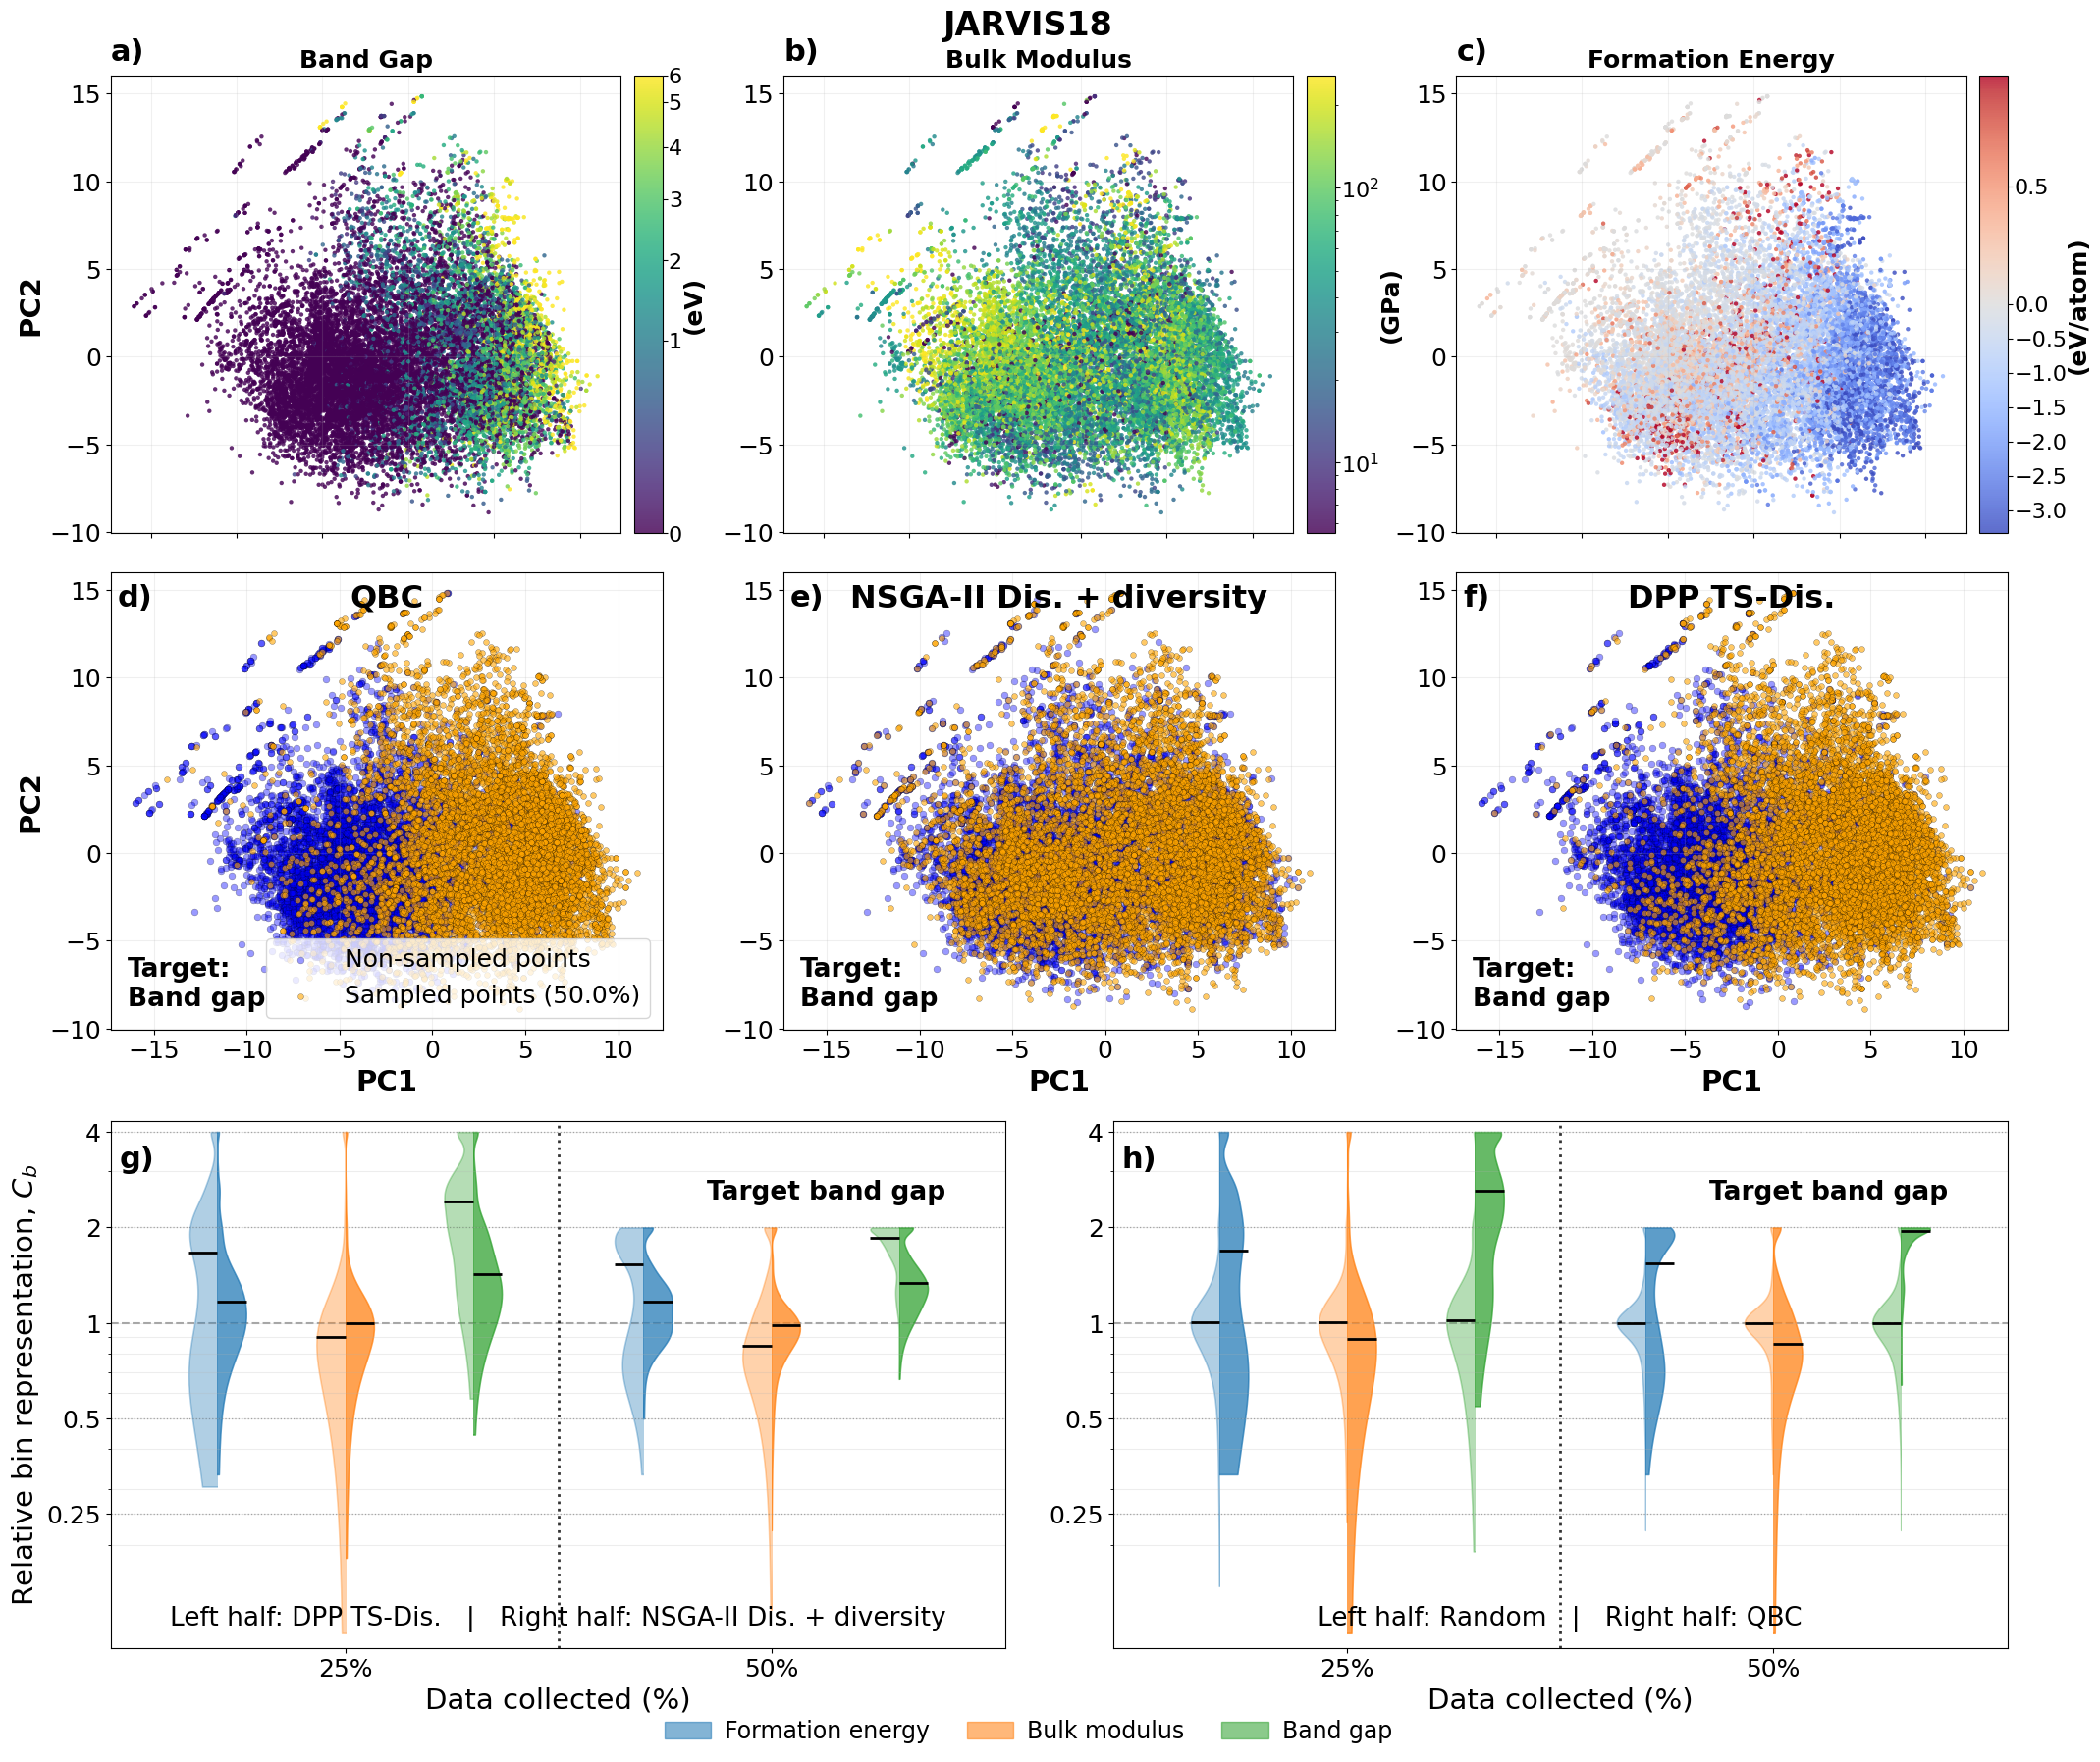

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler


# =============================================================================
# Configuration
# =============================================================================

BASE = Path(
    r"C:\Users\rafae\OneDrive\Imágenes\Documentos\PhDToronto\OLD_FILES"
    r"\PhD Toronto\DatasetGeneration\Better_Acqsition\NewAlg_DFT2"
    r"\WITH_MODIFICATIONS"
)

# -------------------------------------------------------------------------
# Fixed dataset for this combined figure
# -------------------------------------------------------------------------
DATASET_LABEL = "JARVIS18"
DATASET_KEY = "jarvis18"

# -------------------------------------------------------------------------
# Targeted campaign shown in row 2 and row 3
# -------------------------------------------------------------------------
TARGET_LABEL = "Band gap"
TARGET_KEY = "bandgap"

SEED_FOR_PCA_POLICY_ROW = 0
SAMPLED_PERCENT = 50

# Violin row uses all seeds to show variability.
VIOLIN_SEEDS = [0, 1, 2, 3, 4]
VIOLIN_PERCENTAGES = [25, 50]

# -------------------------------------------------------------------------
# Plot settings
# -------------------------------------------------------------------------
FIGSIZE = (21.0, 18.2)
SAVE_DPI = 300

# -------------------------------------------------------------------------
# Font sizes
# -------------------------------------------------------------------------
PANEL_LABEL_SIZE = 22
SUBPLOT_TITLE_SIZE = 23
AXIS_LABEL_SIZE = 21
TICK_LABEL_SIZE = 18
SMALL_TEXT_SIZE = 19
COLORBAR_LABEL_SIZE = 18
COLORBAR_TICK_SIZE = 16


# Row 1: outcome maps
POINT_SIZE_OUTCOME = 10
POINT_ALPHA_OUTCOME = 0.82

# Row 2: sampled / non-sampled
NON_SAMPLED_FACE_COLOR = "blue"
NON_SAMPLED_EDGE_COLOR = "black"
SAMPLED_COLOR = "orange"

NON_SAMPLED_SIZE = 24
SAMPLED_SIZE = 18

NON_SAMPLED_ALPHA = 0.4
SAMPLED_ALPHA = 0.6

# Row 3: violin row
PROPERTY_COLORS = {
    "Formation energy": "tab:blue",
    "Bulk modulus": "tab:orange",
    "Band gap": "tab:green",
}

POLICY_DPP = "DPP-TS-QBC"
POLICY_NSGA = "NSGA-II + diversity"
POLICY_RANDOM = "Random"
POLICY_QBC = "QBC"

PROPERTY_OFFSETS = {
    "Formation energy": -0.30,
    "Bulk modulus": 0.00,
    "Band gap": 0.30,
}

POLICY_OFFSETS = {
    "QBC": -0.08,
    "NSGA-II + diversity": 0.00,
    "DPP-TS-QBC": 0.08,
}

VIOLIN_WIDTH = 0.135
REFERENCE_LEVELS = [0.25, 0.5, 1.0, 2.0, 4.0]

# Outcome-map property info
PROPERTY_INFO = {
    "Band gap": {
        "y_number": 3,
        "title": "Band Gap",
        "colorbar_label": "(eV)",
        "cmap": "viridis",
    },
    "Bulk modulus": {
        "y_number": 2,
        "title": "Bulk Modulus",
        "colorbar_label": "(GPa)",
        "cmap": "viridis",
    },
    "Formation energy": {
        "y_number": 1,
        "title": "Formation Energy",
        "colorbar_label": "(eV/atom)",
        "cmap": "coolwarm",
    },
}

LOW_PERCENTILE = 2
HIGH_PERCENTILE = 98

OUTPUT_FIG = (
    BASE
    / f"{DATASET_KEY}_{TARGET_KEY}_combined_PCA_policies_violin_25_50_updated.png"
)


# =============================================================================
# Data loading
# =============================================================================

def load_x_table(path):
    """
    First column = independent material identifier.
    Remaining columns = features.
    """
    df = pd.read_csv(path)

    if df.shape[1] < 2:
        raise ValueError(f"Expected ID + feature columns in:\n{path}")

    ids = df.iloc[:, 0].rename("material_id")

    X_num = df.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")

    valid_cols = [
        col for col in X_num.columns
        if X_num[col].notna().any()
    ]
    X_num = X_num[valid_cols].copy()

    out = pd.concat([ids, X_num], axis=1)
    out = out[out["material_id"].notna()].copy()

    if out["material_id"].duplicated().any():
        dup = (
            out.loc[out["material_id"].duplicated(), "material_id"]
            .head(10)
            .tolist()
        )
        raise ValueError(
            f"Duplicate IDs found in X file:\n{path}\nExamples: {dup}"
        )

    return out.reset_index(drop=True)


def load_y_table(path, property_name):
    """
    First column = independent material identifier.
    Last numeric column after it = outcome value.
    """
    df = pd.read_csv(path)

    if df.shape[1] < 2:
        raise ValueError(f"Expected ID + outcome columns in:\n{path}")

    ids = df.iloc[:, 0]

    numeric = df.iloc[:, 1:].apply(pd.to_numeric, errors="coerce")

    valid_numeric_cols = [
        c for c in numeric.columns
        if numeric[c].notna().any()
    ]

    if not valid_numeric_cols:
        raise ValueError(f"No numeric outcome column found in:\n{path}")

    y_col = valid_numeric_cols[-1]

    out = pd.DataFrame({
        "material_id": ids,
        property_name: numeric[y_col],
    })

    out = out[
        out["material_id"].notna()
        & out[property_name].notna()
        & np.isfinite(out[property_name])
    ].copy()

    if out["material_id"].duplicated().any():
        dup = (
            out.loc[out["material_id"].duplicated(), "material_id"]
            .head(10)
            .tolist()
        )
        raise ValueError(
            f"Duplicate IDs found in y file:\n{path}\nExamples: {dup}"
        )

    out[property_name] = out[property_name].astype(float)

    return out.reset_index(drop=True)


def load_train_indices(path):
    """
    Read selected material IDs from the `trainIndices` column.
    """
    df = pd.read_csv(path)

    normalized = {
        str(col).strip().lower(): col
        for col in df.columns
    }

    if "trainindices" not in normalized:
        raise KeyError(
            f"Column `trainIndices` not found in:\n{path}\n"
            f"Available columns: {list(df.columns)}"
        )

    col = normalized["trainindices"]
    values = df[col]

    return values[values.notna()].to_numpy()


# =============================================================================
# Policy file resolution
# =============================================================================

def find_trainindices_in_seed_dir(seed_dir):
    if not seed_dir.exists():
        return None

    files = sorted(
        p for p in seed_dir.glob("*.csv")
        if "trainindices" in p.name.lower()
    )

    if not files:
        return None

    return files[0]


def get_qbc_file(dataset_key, target_key, seed):
    exact = (
        BASE
        / "al"
        / "QBC"
        / dataset_key
        / target_key
        / str(seed)
        / f"{dataset_key}_{target_key}_QBC_trainIndices.csv"
    )

    if exact.exists():
        return exact

    seed_dir = (
        BASE
        / "al"
        / "QBC"
        / dataset_key
        / target_key
        / str(seed)
    )

    found = find_trainindices_in_seed_dir(seed_dir)

    if found is not None:
        return found

    raise FileNotFoundError(f"QBC file not found under:\n{seed_dir}")


def get_nsga_file(dataset_key, target_key, seed):
    exact = (
        BASE
        / "al"
        / "grow_EA_QBC_1Obj_withDiversity"
        / dataset_key
        / target_key
        / str(seed)
        / (
            f"{dataset_key}_{target_key}"
            f"grow_EA_QBC_1Obj_withDiversity"
            f"_from3Outcomes{seed}_trainIndices.csv"
        )
    )

    if exact.exists():
        return exact

    seed_dir = (
        BASE
        / "al"
        / "grow_EA_QBC_1Obj_withDiversity"
        / dataset_key
        / target_key
        / str(seed)
    )

    found = find_trainindices_in_seed_dir(seed_dir)

    if found is not None:
        return found

    raise FileNotFoundError(
        f"NSGA-II + diversity file not found under:\n{seed_dir}"
    )


def get_dpp_file(dataset_key, target_key, seed):
    candidate_folders = [
        "grow_TS_QBC_no_diversity_OneTarget",
        "grow_DPP_TS_QBC_OneTarget",
    ]

    for folder in candidate_folders:
        seed_dir = (
            BASE
            / "al"
            / folder
            / dataset_key
            / target_key
            / str(seed)
        )

        found = find_trainindices_in_seed_dir(seed_dir)

        if found is not None:
            return found

    raise FileNotFoundError(
        "DPP-TS-QBC file not found in expected folders."
    )


def get_random_file(dataset_key, seed):
    """
    Random sampling uses the exact project convention:

      al/random/<dataset>/all/<seed>/
      <dataset>_all_random_trainIndices.csv
    """
    exact = (
        BASE
        / "al"
        / "random"
        / dataset_key
        / "all"
        / str(seed)
        / f"{dataset_key}_all_random_trainIndices.csv"
    )

    if exact.exists():
        return exact

    seed_dir = (
        BASE
        / "al"
        / "random"
        / dataset_key
        / "all"
        / str(seed)
    )

    found = find_trainindices_in_seed_dir(seed_dir)

    if found is not None:
        return found

    raise FileNotFoundError(
        f"Random trainIndices file not found under:\n{seed_dir}"
    )


# =============================================================================
# Helpers
# =============================================================================

def get_property_norm(property_name, values):
    values = np.asarray(values, dtype=float)
    finite = values[np.isfinite(values)]

    if len(finite) == 0:
        raise ValueError(f"No finite values for {property_name}")

    if property_name == "Band gap":
        vmin = 0.0
        vmax = np.percentile(finite, HIGH_PERCENTILE)
        if vmax <= vmin:
            vmax = np.max(finite)

        return colors.PowerNorm(
            gamma=0.5,
            vmin=vmin,
            vmax=vmax,
            clip=True,
        )

    elif property_name == "Bulk modulus":
        positive = finite[finite > 0]

        if len(positive) == 0:
            raise ValueError(
                "Bulk modulus has no positive values; LogNorm cannot be used."
            )

        vmin = np.percentile(positive, LOW_PERCENTILE)
        vmax = np.percentile(positive, HIGH_PERCENTILE)

        if vmin <= 0:
            vmin = np.min(positive)
        if vmax <= vmin:
            vmax = np.max(positive)

        return colors.LogNorm(
            vmin=vmin,
            vmax=vmax,
            clip=True,
        )

    elif property_name == "Formation energy":
        vmin = np.percentile(finite, LOW_PERCENTILE)
        vmax = np.percentile(finite, HIGH_PERCENTILE)

        if vmin >= 0:
            vmin = np.min(finite)
        if vmax <= 0:
            vmax = np.max(finite)

        if not (vmin < 0 < vmax):
            vmax_abs = max(abs(np.min(finite)), abs(np.max(finite)))
            vmin = -vmax_abs
            vmax = vmax_abs

        return colors.TwoSlopeNorm(
            vmin=vmin,
            vcenter=0.0,
            vmax=vmax,
        )

    return colors.Normalize(vmin=np.min(finite), vmax=np.max(finite))


def calculate_cb(y_pool, y_selected, bin_edges):
    y_pool = np.asarray(y_pool, dtype=float)
    y_selected = np.asarray(y_selected, dtype=float)

    pool_counts, _ = np.histogram(y_pool, bins=bin_edges)
    selected_counts, _ = np.histogram(y_selected, bins=bin_edges)

    pool_fraction = pool_counts / len(y_pool)
    selected_fraction = selected_counts / len(y_selected)

    valid = pool_counts > 0

    cb = np.full(len(pool_counts), np.nan, dtype=float)
    cb[valid] = selected_fraction[valid] / pool_fraction[valid]

    out = pd.DataFrame({
        "bin": np.arange(len(pool_counts)),
        "N_pool_bin": pool_counts,
        "N_selected_bin": selected_counts,
        "pool_fraction": pool_fraction,
        "selected_fraction": selected_fraction,
        "Cb": cb,
    })

    return out[out["N_pool_bin"] > 0].copy()


def get_sampled_ids(selected_ids_all, sampled_percent):
    n_total = len(selected_ids_all)

    n_sampled = int(np.ceil(sampled_percent / 100.0 * n_total))
    n_sampled = min(max(n_sampled, 1), n_total)

    return selected_ids_all[:n_sampled]


def add_panel_label(ax, label, x=0.00, y=1.02, va="bottom"):
    ax.text(
        x,
        y,
        label,
        transform=ax.transAxes,
        ha="left",
        va=va,
        fontsize=PANEL_LABEL_SIZE,
        fontweight="bold",
    )


# =============================================================================
# Load JARVIS18 data and PCA
# =============================================================================

x_file = BASE / f"xTrainVal_{DATASET_KEY}.csv"
x_df = load_x_table(x_file)

y_tables = {}
merged = x_df.copy()

for property_name, info in PROPERTY_INFO.items():
    y_file = BASE / f"y{info['y_number']}TrainVal_{DATASET_KEY}.csv"
    y_df = load_y_table(y_file, property_name)
    y_tables[property_name] = y_df
    merged = merged.merge(y_df, on="material_id", how="inner")

feature_cols = [c for c in x_df.columns if c != "material_id"]
X = merged[feature_cols].to_numpy(dtype=float)

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

pca = PCA(n_components=2)
scores = pca.fit_transform(X_scaled)

merged["PC1"] = scores[:, 0]
merged["PC2"] = scores[:, 1]

explained = 100 * pca.explained_variance_ratio_

pca_df = merged[["material_id", "PC1", "PC2"]].copy()
pca_lookup = pca_df.set_index("material_id")

# Validate that all three outcomes have the same material IDs after merge.
for property_name, y_df in y_tables.items():
    common_ids = set(merged["material_id"])
    missing = [x for x in y_df["material_id"].tolist() if x not in common_ids]
    # Not an error if the y table has extra rows; the merged set is the one used.

# Outcome lookups and bins for the violin row.
property_lookups = {}
property_bins = {}

for property_name in PROPERTY_INFO:
    series = merged.set_index("material_id")[property_name]
    property_lookups[property_name] = series

    y_pool = merged[property_name].to_numpy(dtype=float)
    n_bins = int(np.ceil(np.sqrt(len(y_pool))))
    property_bins[property_name] = np.linspace(
        np.min(y_pool),
        np.max(y_pool),
        n_bins + 1,
    )

print(f"Common materials used for the combined figure: {len(merged)}")
print(f"Explained variance: PC1={explained[0]:.2f}% | PC2={explained[1]:.2f}%")


# =============================================================================
# Load policy selections for row 2
# =============================================================================

qbc_file_row2 = get_qbc_file(DATASET_KEY, TARGET_KEY, SEED_FOR_PCA_POLICY_ROW)
nsga_file_row2 = get_nsga_file(DATASET_KEY, TARGET_KEY, SEED_FOR_PCA_POLICY_ROW)
dpp_file_row2 = get_dpp_file(DATASET_KEY, TARGET_KEY, SEED_FOR_PCA_POLICY_ROW)

qbc_ids_all_row2 = load_train_indices(qbc_file_row2)
nsga_ids_all_row2 = load_train_indices(nsga_file_row2)
dpp_ids_all_row2 = load_train_indices(dpp_file_row2)

available_ids = set(pca_df["material_id"].tolist())

for policy_name, ids_all in [
    ("QBC", qbc_ids_all_row2),
    ("NSGA-II + diversity", nsga_ids_all_row2),
    ("DPP-TS-QBC", dpp_ids_all_row2),
]:
    missing = [material_id for material_id in ids_all if material_id not in available_ids]
    if missing:
        raise KeyError(
            f"{len(missing)} selected IDs from {policy_name} "
            f"were not found in xTrainVal_{DATASET_KEY}.csv.\n"
            f"Examples: {missing[:10]}"
        )

qbc_sampled = get_sampled_ids(qbc_ids_all_row2, SAMPLED_PERCENT)
nsga_sampled = get_sampled_ids(nsga_ids_all_row2, SAMPLED_PERCENT)
dpp_sampled = get_sampled_ids(dpp_ids_all_row2, SAMPLED_PERCENT)


# =============================================================================
# Compute violin data exactly with the convention from the supplied violin code
# =============================================================================

# Load each outcome independently, exactly as in the original C_b script.
violin_property_files = {
    "Formation energy": BASE / f"y1TrainVal_{DATASET_KEY}.csv",
    "Bulk modulus": BASE / f"y2TrainVal_{DATASET_KEY}.csv",
    "Band gap": BASE / f"y3TrainVal_{DATASET_KEY}.csv",
}

violin_property_tables = {}
violin_property_lookups = {}
violin_property_bins = {}

for property_name, y_file in violin_property_files.items():

    y_df_named = load_y_table(y_file, property_name)

    # Convert to the same simple table convention used by the original violin code.
    table = y_df_named.rename(columns={property_name: "y"})[
        ["material_id", "y"]
    ].copy()

    violin_property_tables[property_name] = table
    violin_property_lookups[property_name] = (
        table.set_index("material_id")["y"]
    )

    y_pool = table["y"].to_numpy(dtype=float)

    n_bins = int(np.ceil(np.sqrt(len(y_pool))))

    violin_property_bins[property_name] = np.linspace(
        np.min(y_pool),
        np.max(y_pool),
        n_bins + 1,
    )


violin_records = []

policy_file_functions = {
    POLICY_DPP: lambda seed: get_dpp_file(DATASET_KEY, TARGET_KEY, seed),
    POLICY_NSGA: lambda seed: get_nsga_file(DATASET_KEY, TARGET_KEY, seed),
    POLICY_RANDOM: lambda seed: get_random_file(DATASET_KEY, seed),
    POLICY_QBC: lambda seed: get_qbc_file(DATASET_KEY, TARGET_KEY, seed),
}

for policy_name, path_func in policy_file_functions.items():

    for seed in VIOLIN_SEEDS:

        indices_file = path_func(seed)
        selected_ids_all = load_train_indices(indices_file)

        # Validate selected IDs against all three outcome tables exactly as
        # in the supplied violin script.
        for property_name, table in violin_property_tables.items():

            available_property_ids = set(
                table["material_id"].tolist()
            )

            missing = [
                x for x in selected_ids_all
                if x not in available_property_ids
            ]

            if missing:
                raise KeyError(
                    f"{len(missing)} selected IDs from {policy_name}, "
                    f"dataset={DATASET_KEY}, target={TARGET_KEY}, seed={seed} "
                    f"were not found in {property_name}.\n"
                    f"File: {indices_file}\n"
                    f"Examples: {missing[:10]}"
                )

        n_available = len(selected_ids_all)

        for pct in VIOLIN_PERCENTAGES:

            frac = pct / 100.0

            n_take = int(np.ceil(frac * n_available))
            n_take = min(max(n_take, 1), n_available)

            selected_ids = selected_ids_all[:n_take]

            for property_name in violin_property_files:

                y_pool = (
                    violin_property_tables[property_name]["y"]
                    .to_numpy(dtype=float)
                )

                y_selected = (
                    violin_property_lookups[property_name]
                    .loc[list(selected_ids)]
                    .to_numpy(dtype=float)
                )

                cb_result = calculate_cb(
                    y_pool=y_pool,
                    y_selected=y_selected,
                    bin_edges=violin_property_bins[property_name],
                )

                cb_result["policy"] = policy_name
                cb_result["seed"] = seed
                cb_result["percent"] = pct
                cb_result["property"] = property_name

                violin_records.append(cb_result)

cb_df = pd.concat(violin_records, ignore_index=True)


# =============================================================================
# Combined figure
# =============================================================================

fig = plt.figure(figsize=FIGSIZE)
gs = GridSpec(
    5,
    3,
    figure=fig,

    # Row 0 = outcome PCA
    # Row 1 = small spacer
    # Row 2 = acquisition PCA
    # Row 3 = small spacer
    # Row 4 = violin plots
    height_ratios=[1.0, 0.085, 1.0, 0.20, 1.15],

    hspace=0.0,
    wspace=0.22,
)

# -------------------------------------------------------------------------
# Row 1: three PCA outcome distributions
# -------------------------------------------------------------------------
row1_axes = []
row1_cbar_axes = []

for col in range(3):
    cell = gs[0, col].subgridspec(
        1,
        2,
        width_ratios=[1.0, 0.055],
        wspace=0.05,
    )

    row1_axes.append(
        fig.add_subplot(cell[0, 0])
    )

    row1_cbar_axes.append(
        fig.add_subplot(cell[0, 1])
    )

row1_panel_info = [
    ("Band gap", "a)"),
    ("Bulk modulus", "b)"),
    ("Formation energy", "c)"),
]

for idx, (ax, cax, (property_name, panel_label)) in enumerate(
    zip(row1_axes, row1_cbar_axes, row1_panel_info)
):

    info = PROPERTY_INFO[property_name]
    values = merged[property_name].to_numpy(dtype=float)
    norm = get_property_norm(property_name, values)

    sc = ax.scatter(
        merged["PC1"],
        merged["PC2"],
        c=values,
        cmap=info["cmap"],
        norm=norm,
        s=POINT_SIZE_OUTCOME,
        alpha=POINT_ALPHA_OUTCOME,
        linewidths=0,
        rasterized=True,
    )

    ax.set_title(
        info["title"],
        fontsize=18,
        fontweight="bold",
    )

    ax.set_xlabel("")

    if idx == 0:
        ax.set_ylabel(
            "PC2",
            fontsize=AXIS_LABEL_SIZE,
            fontweight="bold",
        )

    ax.grid(alpha=0.18)

    # Keep y ticks, but hide the first-row x tick labels so they do not
    # collide with the policy titles in row 2.
    ax.tick_params(axis="y", labelsize=TICK_LABEL_SIZE)
    ax.tick_params(axis="x", labelbottom=False)

    add_panel_label(ax, panel_label)

    cbar = fig.colorbar(
        sc,
        cax=cax,
    )
    cbar.set_label(
        info["colorbar_label"],
        fontsize=COLORBAR_LABEL_SIZE,
        fontweight="bold",
        labelpad=0,
    )
    cbar.ax.tick_params(labelsize=COLORBAR_TICK_SIZE, pad=1)

# -------------------------------------------------------------------------
# Row 2: three policy PCA sampled-vs-non-sampled plots
# -------------------------------------------------------------------------
row2_axes = [
    fig.add_subplot(gs[2, 0], sharex=row1_axes[0], sharey=row1_axes[0]),
    fig.add_subplot(gs[2, 1], sharex=row1_axes[0], sharey=row1_axes[0]),
    fig.add_subplot(gs[2, 2], sharex=row1_axes[0], sharey=row1_axes[0]),
]

row2_plot_info = [
    (row2_axes[0], "QBC", qbc_sampled, "d)"),
    (row2_axes[1], "NSGA-II Dis. + diversity", nsga_sampled, "e)"),
    (row2_axes[2], "DPP TS-Dis.", dpp_sampled, "f)"),
]

for idx, (ax, title, sampled_ids, panel_label) in enumerate(row2_plot_info):

    sampled_id_set = set(sampled_ids)

    non_sampled_mask = ~pca_df["material_id"].isin(sampled_id_set)
    non_sampled = pca_df.loc[non_sampled_mask].copy()

    if len(non_sampled) > 0:
        ax.scatter(
            non_sampled["PC1"],
            non_sampled["PC2"],
            s=NON_SAMPLED_SIZE,
            facecolors=NON_SAMPLED_FACE_COLOR,
            edgecolors=NON_SAMPLED_EDGE_COLOR,
            alpha=NON_SAMPLED_ALPHA,
            linewidths=0.35,
            label="Non-sampled points",
            rasterized=True,
            zorder=1,
        )

    if len(sampled_ids) > 0:
        sampled = pca_lookup.loc[list(sampled_ids)]

        ax.scatter(
            sampled["PC1"],
            sampled["PC2"],
            s=SAMPLED_SIZE,
            c=SAMPLED_COLOR,
            alpha=SAMPLED_ALPHA,
            edgecolors="black",
            linewidths=0.25,
            label=f"Sampled points ({SAMPLED_PERCENT:.1f}%)",
            rasterized=True,
            zorder=2,
        )

    # Put policy title inside the axes to avoid overlap with row 1.
    ax.set_title("")

    ax.text(
        0.5,
        0.975,
        title,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=SUBPLOT_TITLE_SIZE,
        fontweight="bold",
    )

    ax.set_xlabel(
        "PC1",
        fontsize=AXIS_LABEL_SIZE,
        fontweight="bold",
    )

    if idx == 0:
        ax.set_ylabel(
            "PC2",
            fontsize=AXIS_LABEL_SIZE,
            fontweight="bold",
        )

    ax.grid(alpha=0.20)
    ax.tick_params(axis="both", labelsize=TICK_LABEL_SIZE)
    add_panel_label(ax, panel_label, x=0.012, y=0.975, va="top")

    ax.text(
        0.03,
        0.04,
        "Target:\nBand gap",
        transform=ax.transAxes,
        ha="left",
        va="bottom",
        fontsize=SMALL_TEXT_SIZE,
        fontweight="bold",
    )

    if idx == 0:
        ax.legend(
            loc="lower right",
            fontsize=TICK_LABEL_SIZE,
            frameon=True,
        )

# -------------------------------------------------------------------------
# Row 3: original two-panel split-violin format spanning all three columns
# -------------------------------------------------------------------------

row3_subgrid = gs[4, :].subgridspec(
    1,
    2,
    wspace=0.12,
)

ax_v_left = fig.add_subplot(row3_subgrid[0, 0])
ax_v_right = fig.add_subplot(
    row3_subgrid[0, 1],
    sharey=ax_v_left,
)

violin_axes = [ax_v_left, ax_v_right]

percentages = VIOLIN_PERCENTAGES
base_positions = np.arange(1, len(percentages) + 1)

comparisons = [
    (
        ax_v_left,
        POLICY_DPP,
        POLICY_NSGA,
        "",
        "Left half: DPP TS-Dis.   |   Right half: NSGA-II Dis. + diversity",
    ),
    (
        ax_v_right,
        POLICY_RANDOM,
        POLICY_QBC,
        "",
        "Left half: Random   |   Right half: QBC",
    ),
]

all_positive_values = []

for ax, left_policy, right_policy, panel_title, panel_subtitle in comparisons:

    for property_name in violin_property_files:

        color = PROPERTY_COLORS[property_name]
        offset = PROPERTY_OFFSETS[property_name]

        for base_x, pct in zip(base_positions, percentages):

            pos = base_x + offset

            left_values = (
                cb_df.loc[
                    (cb_df["policy"] == left_policy)
                    & (cb_df["property"] == property_name)
                    & (cb_df["percent"] == pct),
                    "Cb",
                ]
                .dropna()
                .to_numpy()
            )

            right_values = (
                cb_df.loc[
                    (cb_df["policy"] == right_policy)
                    & (cb_df["property"] == property_name)
                    & (cb_df["percent"] == pct),
                    "Cb",
                ]
                .dropna()
                .to_numpy()
            )

            # Keep zeros in the data; exclude them only from rendering
            # because a true logarithmic axis cannot show C_b = 0.
            left_values = left_values[left_values > 0]
            right_values = right_values[right_values > 0]

            if len(left_values) > 0:
                all_positive_values.extend(left_values.tolist())

            if len(right_values) > 0:
                all_positive_values.extend(right_values.tolist())

            # Left half violin
            if len(left_values) >= 2:

                vp_left = ax.violinplot(
                    [left_values],
                    positions=[pos],
                    widths=VIOLIN_WIDTH,
                    showmeans=False,
                    showmedians=False,
                    showextrema=False,
                )

                for body in vp_left["bodies"]:
                    body.set_facecolor(color)
                    body.set_edgecolor(color)
                    body.set_alpha(0.35)
                    body.set_linewidth(1.15)

                    # Clip to left half exactly as in the supplied code.
                    verts = body.get_paths()[0].vertices
                    x_min = np.min(verts[:, 0])
                    y_min = np.min(verts[:, 1])
                    y_max = np.max(verts[:, 1])

                    clip = Rectangle(
                        (x_min - 1.0, y_min - 10.0),
                        pos - (x_min - 1.0),
                        y_max - y_min + 20.0,
                        transform=ax.transData,
                    )
                    body.set_clip_path(clip)

            # Right half violin
            if len(right_values) >= 2:

                vp_right = ax.violinplot(
                    [right_values],
                    positions=[pos],
                    widths=VIOLIN_WIDTH,
                    showmeans=False,
                    showmedians=False,
                    showextrema=False,
                )

                for body in vp_right["bodies"]:
                    body.set_facecolor(color)
                    body.set_edgecolor(color)
                    body.set_alpha(0.72)
                    body.set_linewidth(1.15)

                    verts = body.get_paths()[0].vertices
                    x_max = np.max(verts[:, 0])
                    y_min = np.min(verts[:, 1])
                    y_max = np.max(verts[:, 1])

                    clip = Rectangle(
                        (pos, y_min - 10.0),
                        x_max - pos + 1.0,
                        y_max - y_min + 20.0,
                        transform=ax.transData,
                    )
                    body.set_clip_path(clip)

            # Median lines
            if len(left_values) > 0:
                y_med_left = np.median(left_values)

                ax.plot(
                    [pos - VIOLIN_WIDTH / 2.0, pos],
                    [y_med_left, y_med_left],
                    color="black",
                    linewidth=2.0,
                    solid_capstyle="butt",
                )

            if len(right_values) > 0:
                y_med_right = np.median(right_values)

                ax.plot(
                    [pos, pos + VIOLIN_WIDTH / 2.0],
                    [y_med_right, y_med_right],
                    color="black",
                    linewidth=2.0,
                    solid_capstyle="butt",
                )

    # Exact axis convention from the supplied violin code.
    ax.set_yscale("log")

    ax.yaxis.set_major_locator(
        FixedLocator(REFERENCE_LEVELS)
    )

    ax.yaxis.set_major_formatter(
        FixedFormatter(["0.25", "0.5", "1", "2", "4"])
    )

    ax.yaxis.set_minor_formatter(
        NullFormatter()
    )

    for level in REFERENCE_LEVELS:

        if level == 1.0:
            ax.axhline(
                level,
                linestyle="--",
                linewidth=1.5,
                color="gray",
                alpha=0.70,
                zorder=0,
            )
        else:
            ax.axhline(
                level,
                linestyle=":",
                linewidth=0.9,
                color="gray",
                alpha=0.75,
                zorder=0,
            )

    # Separate the 25% and 50% violin groups.
    ax.axvline(1.5, linestyle=":", linewidth=2.0,
               color="black", alpha=0.80, zorder=0)

    ax.set_xlim(
        0.45,
        len(percentages) + 0.55,
    )

    ax.set_xticks(
        base_positions
    )

    ax.set_xticklabels(
        [f"{p}%" for p in percentages]
    )

    ax.set_xlabel(
        "Data collected (%)",
        fontsize=AXIS_LABEL_SIZE,
    )

    # Keep all row-3 annotations INSIDE the axes.
    ax.set_title("")

    ax.text(
        0.80,
        0.89,
        "Target band gap",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=SMALL_TEXT_SIZE,
        fontweight="bold",
    )

    # Put the left/right policy description at the bottom INSIDE the plot.
    ax.text(
        0.5,
        0.03,
        panel_subtitle,
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=SMALL_TEXT_SIZE,
    )

    ax.tick_params(
        axis="both",
        labelsize=TICK_LABEL_SIZE,
    )

    ax.grid(
        axis="y",
        which="both",
        alpha=0.22,
    )

if all_positive_values:

    lower = min(
        0.25,
        min(all_positive_values) * 0.90,
    )

    upper = max(
        4.0,
        max(all_positive_values) * 1.08,
    )

    for ax in violin_axes:
        ax.set_ylim(lower, upper)

ax_v_left.set_ylabel(
    r"Relative bin representation, $C_b$",
    fontsize=AXIS_LABEL_SIZE,
)

# Panel labels for the two violin panels.
add_panel_label(ax_v_left, "g)", x=0.01, y=0.955, va="top")
add_panel_label(ax_v_right, "h)", x=0.01, y=0.955, va="top")

property_handles = [
    Patch(
        facecolor=PROPERTY_COLORS[name],
        edgecolor=PROPERTY_COLORS[name],
        alpha=0.55,
        label=name,
    )
    for name in violin_property_files
]


fig.legend(
    handles=property_handles,
    loc="lower center",
    bbox_to_anchor=(0.5, 0.01),
    ncol=4,
    frameon=False,
    fontsize=17,
    columnspacing=1.6,
    handletextpad=0.6,
)


# -------------------------------------------------------------------------
# Main title and layout
# -------------------------------------------------------------------------
fig.suptitle(
    (
        f"{DATASET_LABEL}"
    ),
    fontsize=24,
    fontweight="bold",
    y=0.992,
)

fig.subplots_adjust(
    top=0.955,
    bottom=0.075,
    left=0.055,
    right=0.975,
)

fig.savefig(
    OUTPUT_FIG,
    dpi=SAVE_DPI,
    bbox_inches="tight",
)

print(f"Saved figure:\n{OUTPUT_FIG}")

plt.show()